<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 2nd exercise: <font color="#C70039">Work with Boxplots for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Date:   10.11.2026
* Student Name : Mohammed Suhan, Mohammed Suhan
* Matriculation No. : 11707086

<img src="https://i2.wp.com/upload.wikimedia.org/wikipedia/commons/thumb/1/1a/Boxplot_vs_PDF.svg/550px-Boxplot_vs_PDF.svg.png?w=578" style="float:center;" width="400">


---------------------------------
**GENERAL NOTE 1**: 
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole. 

**GENERAL NOTE 2**: 
* Please, when commenting source code, just use English language only. 
* When describing an observation please use English language, too
* This applies to all exercises throughout this course.  

---------------------

### <font color="ce33ff">DESCRIPTION</font>:
This notebook allows you for using boxplots to detect anomalies. Try to interpret the boxplot. 

-------------------------------------------------------------------------------------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points. 
If a task is more challenging and consists of several steps, this is indicated as well. 
Make sure you have worked down the task list and commented your doings. 
This should be done by using markdown.<br> 
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date. 
    * set the date too and remove mine.
3. read the entire notebook carefully 
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time. 
4. take the three data sets from exercise 1 and create a boxplot for each of them
5. interpret the visual results and describe them
6. how can you test your data for being normally distributed? 
-----------------------------------------------------------------------------------

In [1]:
# Google Colab setup: make repository files available under the expected relative paths.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repository = "/content/AML"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gheisenberg/AML.git", repository], check=True)
    os.chdir(repository)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(1)

In [3]:
# Draw values from a normal distribution with mean 20 and standard deviation 20.
random_data = rng.normal(loc=20.0, scale=20.0, size=50_000)

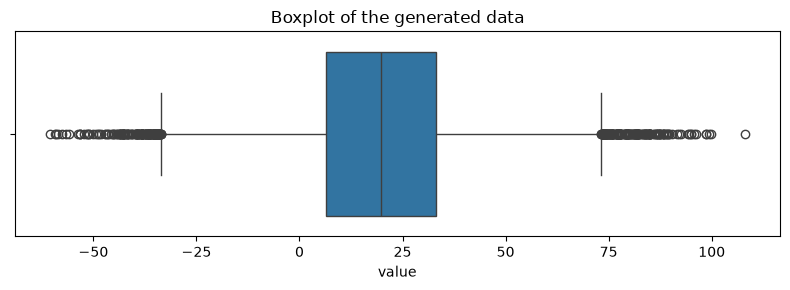

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(x=random_data, ax=ax)
ax.set_title("Boxplot of the generated data")
ax.set_xlabel("value")
plt.tight_layout()
plt.show()

## Task 4: Box plots of my three data sets
I reuse the three data sets from Exercise 1: Bundesliga heights (FIFA 22), IPL first-innings totals and F1 lap times (2024 Italian Grand Prix).

In [5]:
import pandas as pd
import kagglehub
from scipy import stats

# Download (cached from Exercise 1)
fifa_path = kagglehub.dataset_download("stefanoleone992/fifa-22-complete-player-dataset")
ipl_path = kagglehub.dataset_download("patrickb1912/ipl-complete-dataset-20082020")
f1_path = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020")

# 1) Bundesliga heights
players = pd.read_csv(os.path.join(fifa_path, "players_22.csv"), low_memory=False)
heights = players.loc[players["league_name"] == "German 1. Bundesliga", "height_cm"].dropna().astype(float).to_numpy()

# 2) IPL first-innings totals (full 20-over matches, no rain rule)
matches = pd.read_csv(os.path.join(ipl_path, "matches.csv"))
full_matches = matches[(matches["target_overs"] == 20) & (matches["method"].isna())]
ipl_totals = (full_matches["target_runs"].dropna() - 1).astype(float).to_numpy()

# 3) F1 lap times, 2024 Italian Grand Prix (raceId 1136)
RACE_ID = 1136
lap_times = pd.read_csv(os.path.join(f1_path, "lap_times.csv"))
drivers = pd.read_csv(os.path.join(f1_path, "drivers.csv"))
pit_stops = pd.read_csv(os.path.join(f1_path, "pit_stops.csv"))

laps = lap_times[lap_times["raceId"] == RACE_ID].merge(drivers[["driverId", "code"]], on="driverId")
laps["lap_s"] = laps["milliseconds"] / 1000

# Pit-stop time is counted in the lap after the stop, so shift by one
race_pits = pit_stops[pit_stops["raceId"] == RACE_ID][["driverId", "lap"]]
race_pits["lap"] = race_pits["lap"] + 1
race_pits["pit_lap"] = True
laps = laps.merge(race_pits, on=["driverId", "lap"], how="left")
laps["pit_lap"] = laps["pit_lap"].eq(True)

lap_seconds = laps["lap_s"].to_numpy()

datasets = {
    "Bundesliga height (cm)": heights,
    "IPL first-innings total (runs)": ipl_totals,
    "F1 Monza 2024 lap time (s)": lap_seconds,
}

for name, values in datasets.items():
    print(f"{name}: {values.size} values")

Bundesliga height (cm): 551 values
IPL first-innings total (runs): 1062 values
F1 Monza 2024 lap time (s): 1008 values


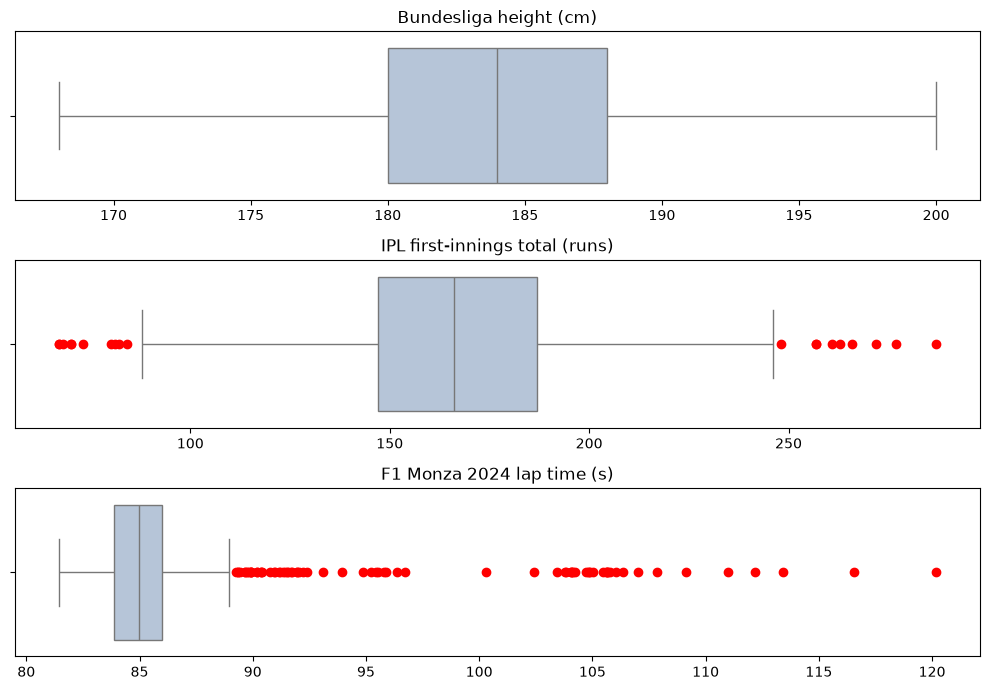

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7))

for ax, (name, values) in zip(axes, datasets.items()):
    sns.boxplot(x=values, ax=ax, color="lightsteelblue",
                flierprops={"markerfacecolor": "red", "markeredgecolor": "red"})
    ax.set_title(name)

plt.tight_layout()
plt.show()

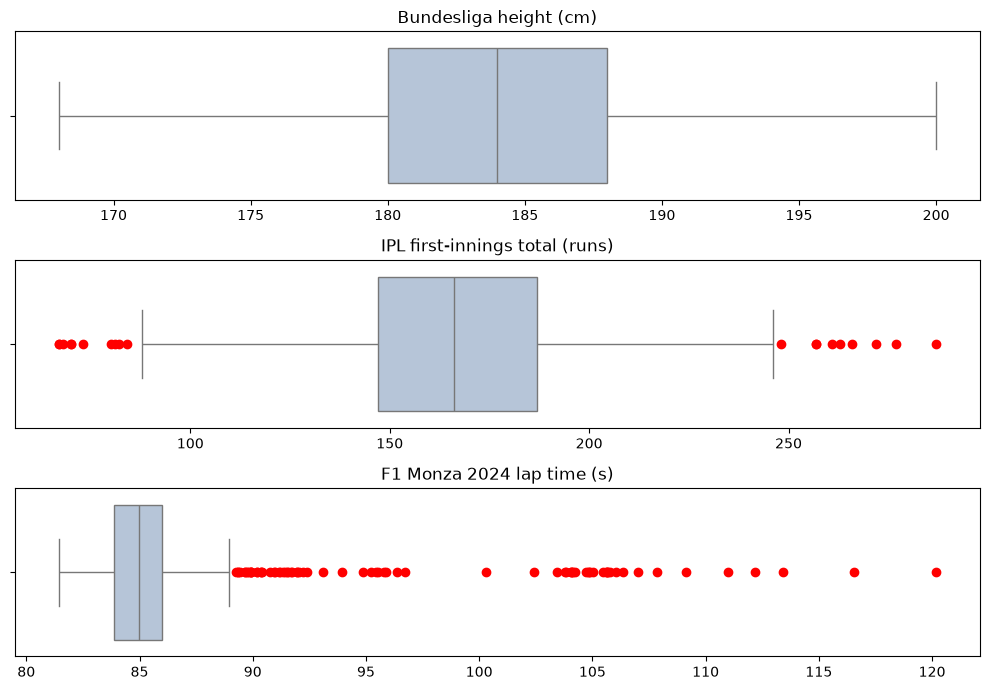

In [7]:
for name, values in datasets.items():
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = np.sum((values < lower) | (values > upper))
    print(f"{name}: Q1={q1}, Q3={q3}, IQR={iqr:.2f}, limits=[{lower:.2f}, {upper:.2f}], "
          f"outliers={n_out} ({n_out / values.size:.2%})")

Bundesliga height (cm): Q1=180.0, Q3=188.0, IQR=8.00, limits=[168.00, 200.00], outliers=0 (0.00%)
IPL first-innings total (runs): Q1=147.0, Q3=187.0, IQR=40.00, limits=[87.00, 247.00], outliers=19 (1.79%)
F1 Monza 2024 lap time (s): Q1=83.8535, Q3=85.97149999999999, IQR=2.12, limits=[80.68, 89.15], outliers=74 (7.34%)


In [8]:
q1, q3 = np.percentile(lap_seconds, [25, 75])
laps["outlier_iqr"] = laps["lap_s"] > q3 + 1.5 * (q3 - q1)
extra = laps[laps["outlier_iqr"] & ~laps["pit_lap"]]
print(extra["lap"].value_counts().sort_index())

lap
1     17
5      3
7      1
10     1
11     2
12     1
14     2
15     3
16     2
17     1
19     2
22     1
23     1
30     1
31     1
32     1
33     1
35     1
36     1
50     1
Name: count, dtype: int64


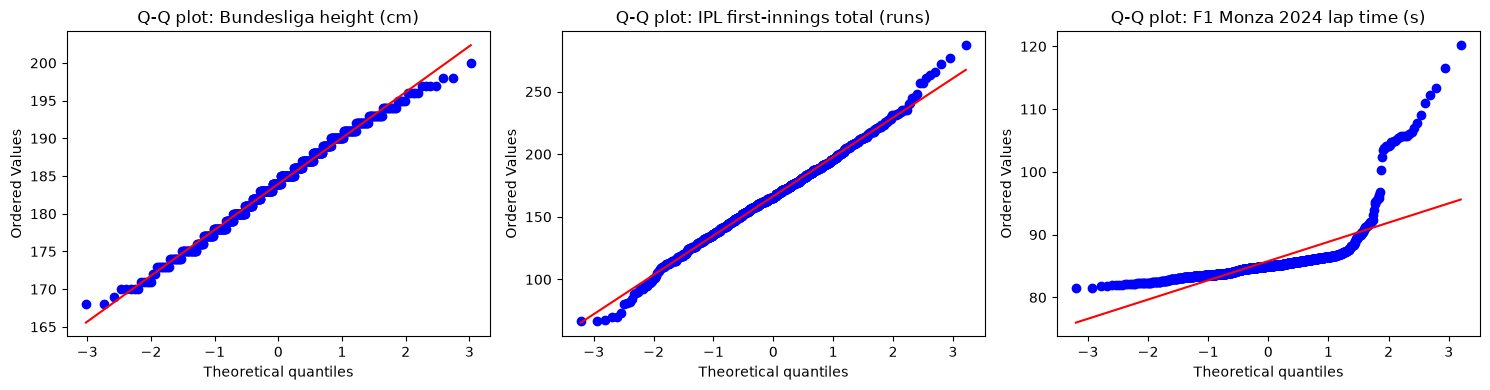

Bundesliga height (cm): Shapiro-Wilk p=0.0075, D'Agostino p=0.0118
IPL first-innings total (runs): Shapiro-Wilk p=0.0029, D'Agostino p=0.0036
F1 Monza 2024 lap time (s): Shapiro-Wilk p=0.0000, D'Agostino p=0.0000


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, values) in zip(axes, datasets.items()):
    stats.probplot(values, dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {name}")
plt.tight_layout()
plt.show()

for name, values in datasets.items():
    sample = values if values.size <= 5000 else np.random.default_rng(1).choice(values, 5000, replace=False)
    w, p_shapiro = stats.shapiro(sample)
    k2, p_dagostino = stats.normaltest(values)
    print(f"{name}: Shapiro-Wilk p={p_shapiro:.4f}, D'Agostino p={p_dagostino:.4f}")

## Task 5: Interpretation

| Data set | 3σ (Ex1) | Box plot (IQR) |
|---|---|---|
| Bundesliga height | 0 | 0 |
| IPL totals | 11 | 19 |
| F1 lap times | 31 | 74 |

**Heights:** The box is symmetric (180 to 188 cm, median 184). There are no outliers. The shortest and tallest players lie exactly on the whisker limits.

**IPL:** The box is symmetric with outliers on both sides. The box plot finds more outliers than 3σ, because the IQR rule is stricter (about ±2.7σ for normal data).

**F1:** The box is very narrow (84 to 86 s) with a long tail to the right. The box plot finds 74 outliers: the 30 pit-stop laps, Tsunoda's retirement lap, 17 first laps and about 26 in- and out-laps around the pit stops. Almost all

## Task 6: How can you test data for normality?

**Visual methods:**
* **Histogram with normal curve:** does the shape match the bell curve? 
* **Q-Q plot:** if the points lie on the straight line, the data is normal. Bends at the ends show heavy tails, light tails or skew.
* **Box plot:** a centered median and equal whiskers suggest symmetry.

**Statistical tests**:
* **Shapiro-Wilk:** the most common test, reliable up to about 5,000 values.
* **D'Agostino-Pearson:** combines skewness and kurtosis.
* **Kolmogorov-Smirnov** and **Anderson-Darling:** compare the whole distribution with a normal one.

**My results:** All three data sets fail both tests (p < 0.05). The Q-Q plots show why: heights have light tails, IPL totals have heavy tails, and the F1 lap times are strongly right-skewed.

**Important:** With large samples, tests reject normality even for very small deviations. Heights and IPL totals are close to the line in the Q-Q plot, so they are approximately normal in practice. Tests and plots should always be used together.